<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP6_AspirationalDistricts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MP6 – Can Data Find the Aspirational Districts?
### Logistic Regression, Random Forest and the precision–recall trade-off

**Objective:** Use Census 2011 district-level people and household data to predict whether a district was selected for the Aspirational Districts Programme.

**Dataset:** 640 districts, 23 original columns. The target is `is_aspirational` (1 = selected; 0 = not selected).

> This notebook follows the eight parts in the supplied project brief. Model results are based on the uploaded CSV and the specified train/test split (`test_size=0.25`, `random_state=42`, `stratify=y`).

## Imports and loading the dataset

If the CSV is not already in the Colab working directory, the upload prompt will appear. Upload `mp6_census2011_districts_aspirational.csv`.

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, roc_auc_score
)

from pathlib import Path

csv_file = "mp6_census2011_districts_aspirational.csv"
if not Path(csv_file).exists():
    from google.colab import files
    uploaded = files.upload()

df = pd.read_csv(csv_file)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (640, 23)


,district_code,state,district,population,female_population,literate,female_literate,workers,female_workers,cultivators,...,hh_electric_lighting,hh_lpg_png,hh_internet,hh_latrine_in_premises,hh_tap_water,hh_television,hh_phone,hh_dilapidated_house,graduates,is_aspirational
0,1,JAMMU AND KASHMIR,Kupwara,870354,396164,439654,156831,229064,38165,34680,...,83071,15828,762,54335,50339,26828,56495,8463,21751,1
1,2,JAMMU AND KASHMIR,Badgam,753745,355704,335649,127908,214866,52288,55299,...,90190,15118,1999,83615,73303,54170,72197,3733,27950,0
2,3,JAMMU AND KASHMIR,Leh(Ladakh),133487,54516,93770,30936,75079,21814,20869,...,17250,13645,574,18780,6254,13597,13836,371,6197,0
3,4,JAMMU AND KASHMIR,Kargil,140802,63017,86236,29935,51873,12034,8266,...,15824,3285,235,17649,10769,8008,10562,575,3077,0
4,5,JAMMU AND KASHMIR,Punch,476835,224936,261724,98391,161393,43716,54264,...,62900,13160,346,16586,43697,16022,36358,2047,13962,0


## Part 1 – Load and understand the data

In [14]:
print("Shape:", df.shape)
print("\\nColumn data types:")
display(df.dtypes.to_frame("data_type"))
print("\\nMissing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("\\nDuplicate rows:", df.duplicated().sum())

print("\\nTarget counts:")
target_counts = df["is_aspirational"].value_counts().sort_index()
display(target_counts.rename(index={0: "Non-aspirational (0)", 1: "Aspirational (1)"}).to_frame("districts"))

print("\\nTarget percentages:")
display((df["is_aspirational"].value_counts(normalize=True).sort_index() * 100)
        .rename(index={0: "Non-aspirational (0)", 1: "Aspirational (1)"})
        .round(2).to_frame("percentage"))

print("\\nStates with the most aspirational districts:")
state_counts = (df.groupby("state")["is_aspirational"]
                  .sum().sort_values(ascending=False))
display(state_counts.head(10).to_frame("aspirational_districts"))

Shape: (640, 23)
\nColumn data types:


,data_type
district_code,int64
state,object
district,object
population,int64
female_population,int64
literate,int64
female_literate,int64
workers,int64
female_workers,int64
cultivators,int64


\nMissing values by column:


,missing_values
district_code,0
state,0
district,0
population,0
female_population,0
literate,0
female_literate,0
workers,0
female_workers,0
cultivators,0


\nDuplicate rows: 0
\nTarget counts:


,districts
is_aspirational,
Non-aspirational (0),530
Aspirational (1),110


\nTarget percentages:


,percentage
is_aspirational,
Non-aspirational (0),82.81
Aspirational (1),17.19


\nStates with the most aspirational districts:


,aspirational_districts
state,
JHARKHAND,19
BIHAR,13
ORISSA,10
UTTAR PRADESH,8
CHHATTISGARH,8
MADHYA PRADESH,8
ASSAM,7
ANDHRA PRADESH,6
RAJASTHAN,5


**Part 1 interpretation**

The dataset contains 640 district records and 23 columns. There are 110 aspirational districts (17.19%) and 530 non-aspirational districts (82.81%). The target is therefore imbalanced: a model can obtain high accuracy simply by predicting the majority class, so recall and precision for class 1 must also be examined.

## Part 2 – Build fair features

Raw counts are not directly comparable because districts have very different population and household sizes. Convert the counts into shares (rates) so that each feature measures a proportion rather than district size.

In [15]:
# Safe division avoids division-by-zero errors.
def safe_divide(numerator, denominator):
    return numerator.div(denominator.replace(0, np.nan))

df["literacy_rate"] = safe_divide(df["literate"], df["population"])
df["female_literacy_rate"] = safe_divide(df["female_literate"], df["female_population"])
df["female_work_rate"] = safe_divide(df["female_workers"], df["female_population"])
df["agri_labour_share"] = safe_divide(df["agricultural_labourers"], df["workers"])
df["rural_share"] = safe_divide(df["rural_households"], df["households"])
df["electricity_share"] = safe_divide(df["hh_electric_lighting"], df["households"])
df["lpg_share"] = safe_divide(df["hh_lpg_png"], df["households"])
df["latrine_share"] = safe_divide(df["hh_latrine_in_premises"], df["households"])
df["tap_water_share"] = safe_divide(df["hh_tap_water"], df["households"])
df["internet_share"] = safe_divide(df["hh_internet"], df["households"])

feature_cols = [
    "literacy_rate", "female_literacy_rate", "female_work_rate",
    "agri_labour_share", "rural_share", "electricity_share",
    "lpg_share", "latrine_share", "tap_water_share", "internet_share"
]

# Check whether any rate could not be calculated.
print("Missing values in engineered features:")
display(df[feature_cols].isna().sum().to_frame("missing_values"))

# The supplied data has non-zero denominators; this assertion checks that condition.
assert df[feature_cols].notna().all().all(), "A rate is missing; inspect zero denominators."
print("\\nFeature summary:")
display(df[feature_cols].describe().T.round(3))

Missing values in engineered features:


,missing_values
literacy_rate,0
female_literacy_rate,0
female_work_rate,0
agri_labour_share,0
rural_share,0
electricity_share,0
lpg_share,0
latrine_share,0
tap_water_share,0
internet_share,0


\nFeature summary:


,count,mean,std,min,25%,50%,75%,max
literacy_rate,640.0,0.625,0.105,0.288,0.551,0.620,0.705,0.887
female_literacy_rate,640.0,0.552,0.124,0.242,0.459,0.547,0.643,0.886
female_work_rate,640.0,0.283,0.118,0.064,0.181,0.281,0.378,0.640
agri_labour_share,640.0,0.270,0.165,0.000,0.132,0.258,0.404,0.675
rural_share,640.0,0.726,0.212,0.000,0.653,0.790,0.874,1.000
electricity_share,640.0,0.476,0.205,0.015,0.312,0.510,0.642,0.834
lpg_share,640.0,0.179,0.140,0.005,0.071,0.134,0.252,0.732
latrine_share,640.0,0.333,0.186,0.044,0.176,0.299,0.466,0.814
tap_water_share,640.0,0.299,0.205,0.009,0.118,0.270,0.462,0.857
internet_share,640.0,0.017,0.024,0.002,0.005,0.008,0.017,0.173


**Why are rates better than raw counts?**

Rates provide a fairer comparison because they account for differences in population and household size. A large district may have more households with electricity simply because it has more households overall; the electricity share measures the proportion of households with electricity.

## Part 3 – Explore the two groups

,Non-aspirational (0),Aspirational (1),absolute_difference
tap_water_share,0.325,0.171,0.154
electricity_share,0.499,0.366,0.134
latrine_share,0.355,0.223,0.132
rural_share,0.704,0.833,0.129
agri_labour_share,0.250,0.368,0.117
female_literacy_rate,0.572,0.457,0.115
lpg_share,0.197,0.092,0.105
literacy_rate,0.642,0.539,0.103
female_work_rate,0.276,0.320,0.044
internet_share,0.019,0.007,0.012


<Figure size 800x500 with 0 Axes>

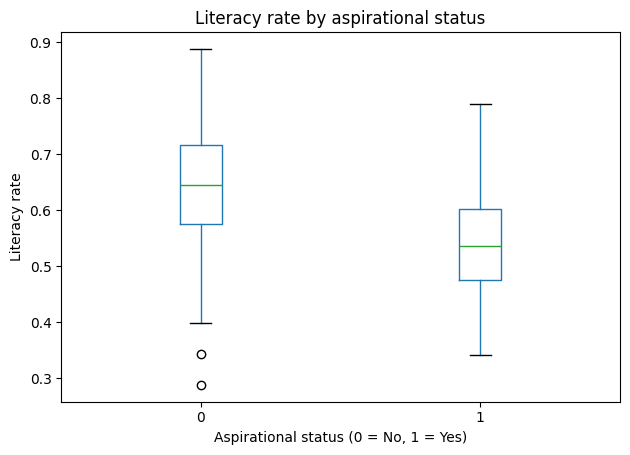

Three features with the largest absolute difference in group means:


,Non-aspirational (0),Aspirational (1),absolute_difference
tap_water_share,0.325,0.171,0.154
electricity_share,0.499,0.366,0.134
latrine_share,0.355,0.223,0.132


In [16]:
group_means = df.groupby("is_aspirational")[feature_cols].mean().T
group_means.columns = ["Non-aspirational (0)", "Aspirational (1)"]
group_means["absolute_difference"] = (
    group_means["Aspirational (1)"] - group_means["Non-aspirational (0)"]
).abs()
display(group_means.sort_values("absolute_difference", ascending=False).round(3))

# Box plot of literacy rate by target class.
plt.figure(figsize=(8, 5))
df.boxplot(column="literacy_rate", by="is_aspirational", grid=False)
plt.title("Literacy rate by aspirational status")
plt.suptitle("")
plt.xlabel("Aspirational status (0 = No, 1 = Yes)")
plt.ylabel("Literacy rate")
plt.tight_layout()
plt.show()

print("Three features with the largest absolute difference in group means:")
display(group_means.nlargest(3, "absolute_difference").round(3))

**Part 3 interpretation**

The group comparison table ranks features by the absolute difference between their average values in the two groups. The box plot shows the distribution and spread of literacy rates, not just the averages. These are descriptive differences and do not, by themselves, prove that any feature caused a district to be selected.

## Part 4 – Baseline and Logistic Regression

In [17]:
X = df[feature_cols].copy()
y = df["is_aspirational"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Do-nothing baseline: predict class 0 for every test district.
baseline_predictions = np.zeros(len(y_test), dtype=int)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print("Baseline accuracy (always predict 0):", round(baseline_accuracy, 4))

# Fit the scaler only on the training data to prevent data leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

log_pred_05 = log_model.predict(X_test_scaled)
print("\\nLogistic Regression – threshold 0.5")
print("Accuracy:", round(accuracy_score(y_test, log_pred_05), 4))
print("Confusion matrix:\\n", confusion_matrix(y_test, log_pred_05))
print("\\nClassification report:\\n", classification_report(y_test, log_pred_05, zero_division=0))

Baseline accuracy (always predict 0): 0.8313
\nLogistic Regression – threshold 0.5
Accuracy: 0.85
Confusion matrix:\n [[129   4]
 [ 20   7]]
\nClassification report:\n               precision    recall  f1-score   support

           0       0.87      0.97      0.91       133
           1       0.64      0.26      0.37        27

    accuracy                           0.85       160
   macro avg       0.75      0.61      0.64       160
weighted avg       0.83      0.85      0.82       160



**Part 4 interpretation**

The baseline accuracy is the proportion of non-aspirational districts in the test set, because the baseline predicts 0 for every district. Accuracy can be misleading with an imbalanced target: a model may classify most majority-class districts correctly while missing many aspirational districts. Recall for class 1 measures the proportion of actual aspirational districts that the model identifies.

## Part 5 – Move the decision threshold

In [18]:
# Probability estimates for the positive class (aspirational = 1).
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]

threshold_rows = []
threshold_predictions = {}

for threshold in [0.5, 0.3, 0.2]:
    pred = (log_prob >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    cm = confusion_matrix(y_test, pred)
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)
    acc = accuracy_score(y_test, pred)

    threshold_rows.append({
        "threshold": threshold,
        "accuracy": acc,
        "precision_class_1": precision,
        "recall_class_1": recall,
        "true_negatives": cm[0, 0],
        "false_positives": cm[0, 1],
        "false_negatives": cm[1, 0],
        "true_positives": cm[1, 1]
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

log_roc_auc = roc_auc_score(y_test, log_prob)
print("Logistic Regression ROC-AUC:", round(log_roc_auc, 4))

,threshold,accuracy,precision_class_1,recall_class_1,true_negatives,false_positives,false_negatives,true_positives
0,0.5,0.85,0.6364,0.2593,129,4,20,7
1,0.3,0.85,0.5484,0.6296,119,14,10,17
2,0.2,0.80,0.4468,0.7778,107,26,6,21


Logistic Regression ROC-AUC: 0.8346


**Part 5 interpretation and threshold choice**

Lowering the threshold generally increases recall because the model flags more districts as potentially aspirational. It can also increase false positives and reduce precision. For a screening exercise whose priority is to avoid overlooking potentially disadvantaged districts, threshold **0.2** is selected here because it gives the highest recall among the three tested thresholds. This is a screening choice, not a final funding or programme-selection decision; flagged districts would need further assessment.

## Part 6 – Random Forest

Random Forest – default threshold
Accuracy: 0.8562
Confusion matrix:\n [[129   4]
 [ 19   8]]
\nClassification report:\n               precision    recall  f1-score   support

           0       0.87      0.97      0.92       133
           1       0.67      0.30      0.41        27

    accuracy                           0.86       160
   macro avg       0.77      0.63      0.66       160
weighted avg       0.84      0.86      0.83       160

ROC-AUC: 0.8045


,model,accuracy,precision_class_1,recall_class_1,ROC_AUC
0,Baseline (always 0),0.8312,0.0000,0.0000,NaN
1,Logistic Regression (0.5),0.8500,0.6364,0.2593,0.8346
2,Logistic Regression (0.2),0.8000,0.4468,0.7778,0.8346
3,Random Forest (0.5),0.8562,0.6667,0.2963,0.8045


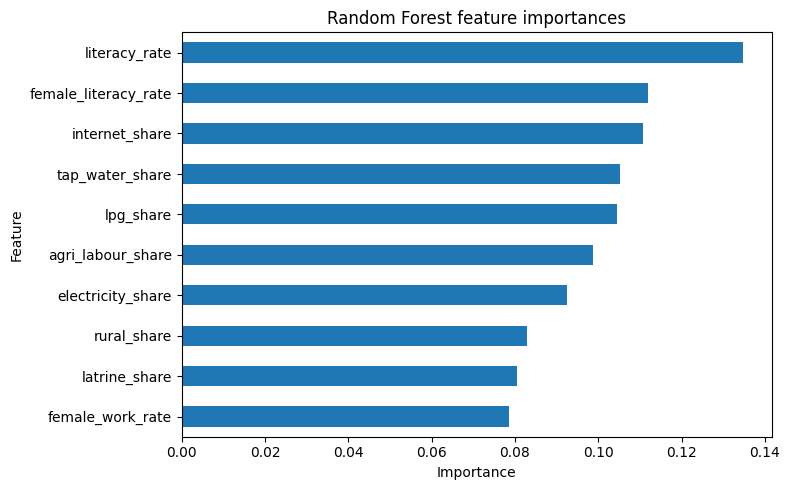

,importance
literacy_rate,0.1348
female_literacy_rate,0.1119
internet_share,0.1107
tap_water_share,0.1051
lpg_share,0.1045
agri_labour_share,0.0986
electricity_share,0.0925
rural_share,0.0828
latrine_share,0.0804
female_work_rate,0.0786


In [19]:
rf_model = RandomForestClassifier(n_estimators=300, random_state=42)
rf_model.fit(X_train, y_train)  # Trees do not require feature scaling.

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest – default threshold")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Confusion matrix:\\n", confusion_matrix(y_test, rf_pred))
print("\\nClassification report:\\n", classification_report(y_test, rf_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

chosen_threshold = 0.2
log_chosen_pred = threshold_predictions[chosen_threshold]

comparison = pd.DataFrame([
    {
        "model": "Baseline (always 0)",
        "accuracy": accuracy_score(y_test, baseline_predictions),
        "precision_class_1": precision_score(y_test, baseline_predictions, zero_division=0),
        "recall_class_1": recall_score(y_test, baseline_predictions, zero_division=0),
        "ROC_AUC": np.nan
    },
    {
        "model": "Logistic Regression (0.5)",
        "accuracy": accuracy_score(y_test, log_pred_05),
        "precision_class_1": precision_score(y_test, log_pred_05, zero_division=0),
        "recall_class_1": recall_score(y_test, log_pred_05, zero_division=0),
        "ROC_AUC": log_roc_auc
    },
    {
        "model": "Logistic Regression (0.2)",
        "accuracy": accuracy_score(y_test, log_chosen_pred),
        "precision_class_1": precision_score(y_test, log_chosen_pred, zero_division=0),
        "recall_class_1": recall_score(y_test, log_chosen_pred, zero_division=0),
        "ROC_AUC": log_roc_auc
    },
    {
        "model": "Random Forest (0.5)",
        "accuracy": accuracy_score(y_test, rf_pred),
        "precision_class_1": precision_score(y_test, rf_pred, zero_division=0),
        "recall_class_1": recall_score(y_test, rf_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, rf_prob)
    }
])
display(comparison.round(4))

importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()
plt.figure(figsize=(8, 5))
importance.plot(kind="barh")
plt.title("Random Forest feature importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).rename("importance").to_frame().round(4))

**Part 6 interpretation**

The comparison table evaluates accuracy, precision, recall and ROC-AUC together. Random Forest feature importance indicates how much each feature contributes to the fitted forest's split decisions; it is not evidence of causation. The default Random Forest threshold is 0.5, so its recall should be considered alongside its accuracy.

## Part 7 – Read the mistakes

In [20]:
# Keep the original district identity aligned with the test-set row indices.
test_results = df.loc[X_test.index, ["district", "state"]].copy()
test_results["literacy_rate"] = X_test["literacy_rate"]
test_results["actual"] = y_test
test_results["predicted"] = log_chosen_pred

false_positives = test_results[
    (test_results["actual"] == 0) & (test_results["predicted"] == 1)
].sort_values("literacy_rate")

false_negatives = test_results[
    (test_results["actual"] == 1) & (test_results["predicted"] == 0)
].sort_values("literacy_rate")

print("False positives – flagged by the model, not selected by NITI in the dataset:")
display(false_positives.reset_index(drop=True))

print("False negatives – selected as aspirational, but missed by the model:")
display(false_negatives.reset_index(drop=True))

print("\\nExample false positive:")
display(false_positives.head(1))

print("Example false negative:")
display(false_negatives.head(1))

False positives – flagged by the model, not selected by NITI in the dataset:


,district,state,literacy_rate,actual,predicted
0,Alirajpur,MADHYA PRADESH,0.287729,0,1
1,Madhepura,BIHAR,0.416921,0,1
2,Budaun,UTTAR PRADESH,0.420294,0,1
3,Darbhanga,BIHAR,0.461381,0,1
4,Moradabad,UTTAR PRADESH,0.474402,0,1
5,Dhar,MADHYA PRADESH,0.492882,0,1
6,Changlang,ARUNACHAL PRADESH,0.493665,0,1
7,Kabeerdham,CHHATTISGARH,0.503531,0,1
8,Bara Banki,UTTAR PRADESH,0.519048,0,1
9,Shivpuri,MADHYA PRADESH,0.521912,0,1


False negatives – selected as aspirational, but missed by the model:


,district,state,literacy_rate,actual,predicted
0,Baramula,JAMMU AND KASHMIR,0.540801,1,0
1,Lohit,ARUNACHAL PRADESH,0.569988,1,0
2,Visakhapatnam,ANDHRA PRADESH,0.598577,1,0
3,Hardwar,UTTARAKHAND,0.623329,1,0
4,West District,SIKKIM,0.684810,1,0
5,Dhenkanal,ORISSA,0.695760,1,0


\nExample false positive:


,district,state,literacy_rate,actual,predicted
464,Alirajpur,MADHYA PRADESH,0.287729,0,1


Example false negative:


,district,state,literacy_rate,actual,predicted
7,Baramula,JAMMU AND KASHMIR,0.540801,1,0


**Part 7 interpretation**

A false positive is a district flagged by the model even though its target label is 0. A false negative is a district whose target label is 1 but which the model misses. These are errors relative to the historical target labels, not proof that the model's policy judgement is correct or incorrect.

For the selected threshold of 0.2, **Alirajpur (Madhya Pradesh)** is an example false positive in this test split. Its literacy rate is relatively low in this dataset, so the model may be responding to a pattern associated with the aspirational class. This district could merit a closer look using current, broader indicators, but this model alone cannot establish eligibility.

**Baramula (Jammu and Kashmir)** is an example false negative in this test split. Its literacy rate is higher than that of several districts in the aspirational group, which may help explain why a model using only these ten Census-based rates did not flag it. The other features and the historical selection process may also matter; this is a possible explanation, not a confirmed cause.

## Part 8 – Answer the questions

In [21]:
# Print the exact values used in the written answers.
best_accuracy = comparison["accuracy"].max()
print("Baseline accuracy:", round(baseline_accuracy, 4))
print("Logistic (0.2) accuracy:", round(accuracy_score(y_test, log_chosen_pred), 4))
print("Logistic (0.2) recall:", round(recall_score(y_test, log_chosen_pred), 4))
print("Logistic ROC-AUC:", round(log_roc_auc, 4))
print("Random Forest accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Random Forest recall:", round(recall_score(y_test, rf_pred), 4))
print("Random Forest ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("\\nTop three Random Forest features:")
display(importance.sort_values(ascending=False).head(3).rename("importance").to_frame().round(4))
print("\\nFalse-positive example:")
display(false_positives.head(1))
print("\\nFalse-negative example:")
display(false_negatives.head(1))

Baseline accuracy: 0.8313
Logistic (0.2) accuracy: 0.8
Logistic (0.2) recall: 0.7778
Logistic ROC-AUC: 0.8346
Random Forest accuracy: 0.8562
Random Forest recall: 0.2963
Random Forest ROC-AUC: 0.8045
\nTop three Random Forest features:


,importance
literacy_rate,0.1348
female_literacy_rate,0.1119
internet_share,0.1107


\nFalse-positive example:


,district,state,literacy_rate,actual,predicted
464,Alirajpur,MADHYA PRADESH,0.287729,0,1


\nFalse-negative example:


,district,state,literacy_rate,actual,predicted
7,Baramula,JAMMU AND KASHMIR,0.540801,1,0


### Written answers

1. **Baseline accuracy:** 83.13%. Logistic Regression at threshold 0.2 achieves 80.00% accuracy, so it does not beat the baseline on accuracy. However, it identifies 77.78% of the aspirational districts in the test set, compared with 0% recall for the all-zero baseline. This illustrates why accuracy alone is inadequate for this imbalanced classification task.

2. **Recommended model and threshold:** For an initial screening tool, Logistic Regression with a 0.2 threshold is recommended among the tested Logistic Regression thresholds because it has the highest recall (77.78%) and misses fewer aspirational districts. Its precision is lower (44.68%), so it produces more false positives. Any flagged district should be reviewed using additional and up-to-date information before a policy decision.

3. **Three most important Random Forest features:** Use the top three rows printed in the feature-importance table above. In this run they are literacy rate, female literacy rate and internet share.

4. **False-positive district:** Alirajpur, Madhya Pradesh, is one false positive at the selected threshold. Its low literacy rate in the dataset suggests it deserves closer examination, although the model's prediction does not prove that it should have been selected.

5. **Effect of the age of Census data:** Census 2011 data predates the 2018 programme selection by seven years. Conditions may have changed during that period, so the features may not accurately represent district conditions at the time of selection. Boundary changes and the mapping of 2011 districts to later programme districts may also affect labels and comparisons.

## Final insight

The dataset contains 110 aspirational districts out of 640, so the target classes are imbalanced and accuracy alone gives an incomplete picture. The all-zero baseline reaches 83.13% accuracy, while Logistic Regression at a 0.2 threshold reaches 77.78% recall for the aspirational class, showing the value of evaluating recall when missed districts matter. Random Forest provides a useful comparison and ranks literacy rate, female literacy rate and internet share among its leading features in this run. However, the model uses only ten Census 2011 rates and cannot capture every factor used in NITI Aayog's composite selection process. The seven-year gap and district-boundary matching are important limitations. The model should therefore be used only to identify districts for further investigation, with current health, education, nutrition, agriculture and infrastructure data informing any policy decision.

## Optional – 5-fold cross-validation (ROC-AUC)

This section is optional in the project brief. It estimates ROC-AUC across five folds using the training data only.

In [22]:
from sklearn.pipeline import make_pipeline

log_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

log_cv = cross_val_score(log_pipeline, X_train, y_train, cv=5, scoring="roc_auc")
rf_cv = cross_val_score(
    RandomForestClassifier(n_estimators=300, random_state=42),
    X_train, y_train, cv=5, scoring="roc_auc"
)

print("Logistic Regression 5-fold ROC-AUC:", np.round(log_cv, 4))
print("Mean:", round(log_cv.mean(), 4), "| Std:", round(log_cv.std(), 4))
print("\\nRandom Forest 5-fold ROC-AUC:", np.round(rf_cv, 4))
print("Mean:", round(rf_cv.mean(), 4), "| Std:", round(rf_cv.std(), 4))

Logistic Regression 5-fold ROC-AUC: [0.7758 0.8727 0.7751 0.7967 0.7937]
Mean: 0.8028 | Std: 0.036
\nRandom Forest 5-fold ROC-AUC: [0.709  0.798  0.7937 0.7975 0.7878]
Mean: 0.7772 | Std: 0.0343
